In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import rankdata

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, matthews_corrcoef, brier_score_loss, confusion_matrix,
                             log_loss, roc_curve)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

N_OUTER_REP   = 10        # outer repeats x 5 folds = 50 outer test folds
N_INNER_REP   = 3         # repeated cross-fitting: 3 x 5-fold OOF per learner
N_AUDIT_REP   = 3         # repeats for the leakage audit

In [2]:
raw = pd.read_csv("heart.csv")
print("Raw shape:", raw.shape, "\nDplicate rows:", int(raw.duplicated().sum()))
df_u = raw.drop_duplicates().reset_index(drop=True)
print("Unique patients:", len(df_u), "\nClass balance (target=1):", round(df_u.target.mean(), 3))

mult = raw.groupby(list(raw.columns)).size()
print("\nUnique record is repeated (times for each):", mult.value_counts().sort_index().to_dict())

# check missing values
print("\nNaN in the file:", int(raw.isna().sum().sum()))
print("thal == 0 (invalid, 1->3 allowed):", int((df_u.thal == 0).sum()))
print("ca == 4 (invalid, 0->3 allowed):", int((df_u.ca == 4).sum()))

Raw shape: (1025, 14) 
Dplicate rows: 723
Unique patients: 302 
Class balance (target=1): 0.543

Unique record is repeated (times for each): {3: 187, 4: 114, 8: 1}

NaN in the file: 0
thal == 0 (invalid, 1->3 allowed): 2
ca == 4 (invalid, 0->3 allowed): 4


In [3]:

def add_clinical_features(d):
    d = d.copy()
    d["hr_reserve"]      = d["thalach"] / (220.0 - d["age"]).clip(lower=1)  
    d["oldpeak_x_exang"] = d["oldpeak"] * d["exang"]  
    return d

def repair_missing(d):
    d = d.copy()
    d.loc[d["thal"] == 0, "thal"] = np.nan 
    d.loc[d["ca"]   == 4, "ca"]   = np.nan
    return d

ORIG  = [c for c in raw.columns if c != "target"]
df    = add_clinical_features(df_u)
y_all = df["target"].values
X_orig = df[ORIG]                              
X_rep  = repair_missing(df.drop(columns="target")) 
print("NaNs exposed after repair:", int(X_rep.isna().sum().sum()))

NaNs exposed after repair: 6


In [8]:
def paper_estimators():
    return [("lr",  make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))),
            ("nb",  GaussianNB()),
            ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
            ("dt",  DecisionTreeClassifier(criterion="entropy", random_state=42)),
            ("rf",  RandomForestClassifier(n_estimators=100, random_state=42)),
            ("xgb", XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=1, verbosity=0))]

def paper_stack():
    return StackingClassifier(paper_estimators(), final_estimator=LogisticRegression(random_state=42),
                              cv=StratifiedKFold(5, shuffle=True, random_state=42))

def leakage_audit(n_rep):
    feats = [c for c in raw.columns if c != "target"]
    sets = {"Raw 1,025 rows (paper protocol)": raw, "302 unique patients (leak-free)": df_u}
    models = {"Decision Tree": lambda: DecisionTreeClassifier(criterion="entropy", random_state=42),
              "Random Forest": lambda: RandomForestClassifier(n_estimators=100, random_state=42),
              "Paper stacking": paper_stack}
    rows = []
    for dname, d in sets.items():
        Xd, yd = d[feats], d["target"].values
        for k, (tr, te) in enumerate(RepeatedStratifiedKFold(n_splits=5, n_repeats=n_rep, random_state=0).split(Xd, yd)):
            tr_keys = set(map(tuple, Xd.iloc[tr].values))
            twin = np.mean([tuple(r) in tr_keys for r in Xd.iloc[te].values])
            for mname, mk in models.items():
                m = mk().fit(Xd.iloc[tr], yd[tr]); p = m.predict_proba(Xd.iloc[te])[:, 1]
                rows.append(dict(data=dname, model=mname, fold=k, Accuracy=accuracy_score(yd[te], p >= .5),
                                 AUC=roc_auc_score(yd[te], p)))
    return pd.DataFrame(rows)

t0 = time.time()
audit = leakage_audit(N_AUDIT_REP)
audit_tbl = audit.groupby(["data", "model"])[["Accuracy", "AUC"]].mean().round(4)
audit_tbl.to_csv("leakage_audit.csv")
print(f"(audit took {time.time()-t0:.0f}s)")
audit_tbl

(audit took 36s)


Accuracy     AUC  \
data                            model                              
302 unique patients (leak-free) Decision Tree     0.7561  0.7547   
                                Paper stacking    0.8265  0.9037   
                                Random Forest     0.8232  0.9097   
Raw 1,025 rows (paper protocol) Decision Tree     0.9932  0.9933   
                                Paper stacking    0.9941  0.9999   
                                Random Forest     0.9951  0.9999   

                                                test_rows_with_twin_in_train  
data                            model                                         
302 unique patients (leak-free) Decision Tree                         0.0000  
                                Paper stacking                        0.0000  
                                Random Forest                         0.0000  
Raw 1,025 rows (paper protocol) Decision Tree                         0.9792  
                                Paper stacking                        0.9792  
                                Random Forest                         0.9792

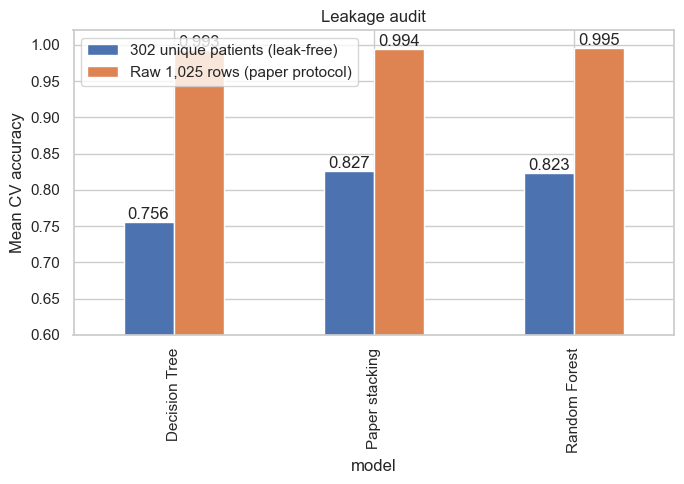

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
a = audit.groupby(["model", "data"])["Accuracy"].mean().unstack()
a.plot.bar(ax=ax)
ax.set_ylim(0.6, 1.02)
ax.set_ylabel("Mean CV accuracy")
ax.set_title("Leakage audit")
for c in ax.containers: 
    ax.bar_label(c, fmt="%.3f")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
categorical = ["cp", "restecg", "slope", "thal"]
order = ["ca"]
numeric = ["age", "trestbps", "chol", "thalach", "oldpeak", "hr_reserve", "oldpeak_x_exang"]
bina = ["sex", "fbs", "exang"]
all_features = numeric + bina + categorical + order
VIEWS = {"exercise":     ["thalach", "exang", "oldpeak", "slope", "hr_reserve", "oldpeak_x_exang", "restecg"],
         "presentation": ["age", "sex", "cp"],
         "vascular":     ["ca", "thal"],
         "metabolic":    ["trestbps", "chol", "fbs"]}

def make_pre(features, spline=False):
    tr = []
    c = [f for f in categorical if f in features]
    if c: tr.append(("categorical", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), c))
    o = [f for f in order if f in features]
    if o: tr.append(("order", make_pipeline(SimpleImputer(strategy="most_frequent"), StandardScaler()), o))
    n = [f for f in numeric if f in features]
    if n:
        tr.append(("numeric", make_pipeline(StandardScaler(), SplineTransformer(n_knots=4, degree=3, include_bias=False), StandardScaler())
                   if spline else StandardScaler(), n))
    b = [f for f in bina if f in features]
    if b: tr.append(("bina", "passthrough", b))
    return ColumnTransformer(tr)

def paper_learners():
    return {"LR":  LogisticRegression(max_iter=2000, random_state=42),
            "NB":  GaussianNB(),
            "KNN": KNeighborsClassifier(n_neighbors=5),
            "DT":  DecisionTreeClassifier(criterion="entropy", random_state=42),
            "RF":  RandomForestClassifier(n_estimators=100, random_state=42),
            "XGB": XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=1, verbosity=0)}

def build_pool():
    pool = {n: (m, all_features) for n, m in paper_learners().items()}
    # extra algorithms only used in the 'A4x' ablation (does adding more *algorithms* help?)
    extra = {"SVM": (SVC(probability=True, random_state=42), all_features),
             "ET":  (ExtraTreesClassifier(n_estimators=100, random_state=42), all_features),
             "GAM": (LogisticRegression(max_iter=3000, C=0.1, random_state=42), all_features)}   # spline-LR
    views = {"V_" + v: (LogisticRegression(max_iter=2000, random_state=42), cols) for v, cols in VIEWS.items()}
    return pool, views, extra

def oof_and_test(learners, Xtr, ytr, Xte, R, seed):
    oof = {n: np.zeros((R, len(ytr))) for n in learners}; tst = {}
    for n, (m, cols) in learners.items():
        pipe = Pipeline([("pre", make_pre(cols, spline=(n == "GAM"))), ("m", m)])
        for r in range(R):
            for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed * 1000 + r).split(Xtr, ytr):
                oof[n][r, va] = clone(pipe).fit(Xtr.iloc[tr], ytr[tr]).predict_proba(Xtr.iloc[va])[:, 1]
        tst[n] = clone(pipe).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    return oof, tst

In [14]:
class NonNegLogitStacker(BaseEstimator, ClassifierMixin):
    def __init__(self, lams=(0.01, 0.1, 1.0, 10.0), eps=0.01, seed=42):
        self.lams, self.eps, self.seed = lams, eps, seed
    def _z(self, P):
        P = np.clip(P, self.eps, 1 - self.eps); return np.log(P / (1 - P))
    @staticmethod
    def _fit(Z, y, lam):
        k = Z.shape[1]
        def f(th):
            w, b = th[:k], th[k]; s = Z @ w + b; g = expit(s) - y
            return np.sum(np.logaddexp(0, s) - y * s) + 0.5 * lam * w @ w, np.r_[Z.T @ g + lam * w, g.sum()]
        r = minimize(f, np.r_[np.full(k, 1.0 / k), 0.0], jac=True, method="L-BFGS-B", bounds=[(0, None)] * k + [(None, None)])
        return r.x[:k], r.x[k]
    def fit(self, P, y):
        Z, y = self._z(P), np.asarray(y); best, bl = self.lams[0], np.inf
        for lam in self.lams:
            ls = []
            for tr, va in StratifiedKFold(5, shuffle=True, random_state=self.seed).split(Z, y):
                w, b = self._fit(Z[tr], y[tr], lam)
                ls.append(log_loss(y[va], np.clip(expit(Z[va] @ w + b), 1e-6, 1 - 1e-6), labels=[0, 1]))
            if np.mean(ls) < bl: best, bl = lam, np.mean(ls)
        self.lam_ = best; self.w_, self.b_ = self._fit(Z, y, best); self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, P):
        p = expit(self._z(P) @ self.w_ + self.b_); return np.c_[1 - p, p]
    def predict(self, P): return (self.predict_proba(P)[:, 1] >= 0.5).astype(int)

def caruana(oof, y, rounds=25):
    cnt = {n: 0 for n in oof}; cur, k = np.zeros(len(y)), 0
    for _ in range(rounds):
        losses = {n: brier_score_loss(y, (cur * k + oof[n]) / (k + 1)) for n in oof}
        b = min(losses, key=losses.get); cnt[b] += 1; cur, k = (cur * k + oof[b]) / (k + 1), k + 1
    return cnt

def best_f2_threshold(y, p):
    grid = np.linspace(0.1, 0.9, 81)
    return float(grid[int(np.argmax([fbeta_score(y, (p >= t).astype(int), beta=2) for t in grid]))])

def selective_band(y_oof, p_oof, target_acc=0.90, min_cov=0.50):
    chosen = 0.0
    for d in np.arange(0.0, 0.45, 0.01):
        acc_mask = np.abs(p_oof - 0.5) >= d
        if acc_mask.mean() < min_cov: break
        chosen = d
        if ((p_oof[acc_mask] >= 0.5) == y_oof[acc_mask]).mean() >= target_acc: break
    return float(chosen)

def selective_eval(y, p, delta):
    acc_mask = np.abs(p - 0.5) >= delta; yh = (p >= 0.5).astype(int)
    cov = acc_mask.mean()
    return dict(Coverage=cov,
                SelAccuracy=(yh[acc_mask] == y[acc_mask]).mean() if acc_mask.any() else np.nan,
                AbstainedAccuracy=(yh[~acc_mask] == y[~acc_mask]).mean() if (~acc_mask).any() else np.nan,
                FN_accepted=int(((yh == 0) & (y == 1) & acc_mask).sum()), FN_all=int(((yh == 0) & (y == 1)).sum()))

def metrics(y, p, thr=0.5):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, yh), Precision=precision_score(y, yh, zero_division=0),
                Recall=recall_score(y, yh, zero_division=0), Specificity=tn / (tn + fp),
                F1=f1_score(y, yh, zero_division=0), F2=fbeta_score(y, yh, beta=2, zero_division=0),
                MCC=matthews_corrcoef(y, yh), AUC=roc_auc_score(y, p), Brier=brier_score_loss(y, p),
                TP=tp, TN=tn, FP=fp, FN=fn)

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for i in range(bins):
        m = (p >= edges[i]) & ((p < edges[i + 1]) if i < bins - 1 else (p <= edges[i + 1]))
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

In [36]:
algorithm_paper = ["LR", "NB", "KNN", "DT", "RF", "XGB"]
view_n = ["V_" + v for v in VIEWS]
method = ["P0 Paper stacking (reproduced)", "repair/encode", "non-neg logit meta", "repeated cross-fitting",
                "CMV-Stack (proposed)", "SVM,ET,GAM", "Caruana", "high-sensitivity", "P0", "base:LR"]
high_sen = "high-sensitivity"

def run_experiment(n_outer_rep, seed0=0, n_inner_rep=N_INNER_REP):
    pool, views, extra = build_pool()
    L_all = {**pool, **views, **extra}
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_outer_rep, random_state=seed0)
    rows, preds, sel_rows, weights = [], [], [], []
    t0 = time.time()
    for fi, (tr, te) in enumerate(rskf.split(X_rep, y_all)):
        ytr, yte = y_all[tr], y_all[te]
        rec = {}
        # ---- P0: the paper's pipeline as reproduced in Part 1 (raw features, de-duplicated data)
        rec["P0 Paper stacking (reproduced)"] = (stack_clf.fit(X_orig.iloc[tr], ytr).predict_proba(X_orig.iloc[te])[:, 1], 0.5)
        # ---- all learners on repaired data, with nested repeated cross-fitting
        oof, tst = oof_and_test(L_all, X_rep.iloc[tr], ytr, X_rep.iloc[te], n_inner_rep, seed=fi + seed0)
        O = lambda names, r: np.column_stack([(oof[n].mean(0) if r == "avg" else oof[n][r]) for n in names])
        T = lambda names: np.column_stack([tst[n] for n in names])
        for n in list(pool) + ["SVM", "ET", "GAM"]:
            rec[f"base:{n}"] = (tst[n], 0.5)
        rec["repair/encode"]          = (LogisticRegression(random_state=42).fit(O(algorithm_paper, 0), ytr).predict_proba(T(algorithm_paper))[:, 1], 0.5)
        rec["non-neg logit meta"]     = (NonNegLogitStacker().fit(O(algorithm_paper, 0), ytr).predict_proba(T(algorithm_paper))[:, 1], 0.5)
        rec["repeated cross-fitting"] = (NonNegLogitStacker().fit(O(algorithm_paper, "avg"), ytr).predict_proba(T(algorithm_paper))[:, 1], 0.5)
        pv = algorithm_paper + view_n
        meta4 = NonNegLogitStacker().fit(O(pv, "avg"), ytr); p4 = meta4.predict_proba(T(pv))[:, 1]
        rec["CMV-Stack (proposed)"]    = (p4, 0.5)
        pe = list(L_all)
        rec["SVM,ET,GAM"]            = (NonNegLogitStacker().fit(O(pe, "avg"), ytr).predict_proba(T(pe))[:, 1], 0.5)
        cnt = caruana({n: oof[n].mean(0) for n in pe}, ytr)
        rec["Caruana"]         = (sum(cnt[n] * tst[n] for n in pe) / sum(cnt.values()), 0.5)
        # ---- decision layer (tau*, selective band) learned on inner-OOF only; applied to the proposed model AND to controls
        skf = StratifiedKFold(5, shuffle=True, random_state=42)
        oofm4 = cross_val_predict(NonNegLogitStacker(), O(pv, "avg"), ytr, cv=skf, method="predict_proba")[:, 1]
        oofm1 = cross_val_predict(LogisticRegression(random_state=42), O(algorithm_paper, 0), ytr, cv=skf, method="predict_proba")[:, 1]
        oofLR = oof["LR"].mean(0)
        oofP0 = cross_val_predict(stack_clf, X_orig.iloc[tr], ytr, cv=StratifiedKFold(3, shuffle=True, random_state=42), method="predict_proba")[:, 1]
        p0, p1, pLR = rec["P0 Paper stacking (reproduced)"][0], rec["repair/encode"][0], tst["LR"]
        dec = {"P0": (p0, oofP0), "LR": (pLR, oofLR), "A1": (p1, oofm1), "A4": (p4, oofm4)}
        for nm, (p, oo) in dec.items():
            tau, dl = best_f2_threshold(ytr, oo), selective_band(ytr, oo)
            s = selective_eval(yte, p, dl); s.update(fold=fi, model=nm, delta=dl, tau=tau); sel_rows.append(s)
            if nm == "P0": rec["P0*"] = (p, tau)
            if nm == "LR": rec["base:LR"] = (pLR, tau)
            if nm == "A4": rec["high-sensitivity"] = (p4, tau)
        weights.append(dict(zip(pv, meta4.w_)) | dict(fold=fi, lam=meta4.lam_, bias=meta4.b_))
        for k, (p, thr) in rec.items():
            r = metrics(yte, p, thr); r.update(fold=fi, repeat=fi // 5, method=k, tau=thr); rows.append(r)
            preds.append(pd.DataFrame(dict(idx=te, p=p, y=yte, fold=fi, repeat=fi // 5, method=k, thr=thr)))
        if fi % 5 == 4: print(f"  outer repeat {fi//5 + 1}/{n_outer_rep} done  ({time.time()-t0:.0f}s)", flush=True)
    return pd.DataFrame(rows), pd.concat(preds, ignore_index=True), pd.DataFrame(sel_rows), pd.DataFrame(weights)

res, preds, sel, wts = run_experiment(N_OUTER_REP)

  outer repeat 1/10 done  (60s)
  outer repeat 2/10 done  (121s)
  outer repeat 3/10 done  (180s)
  outer repeat 4/10 done  (242s)
  outer repeat 5/10 done  (303s)
  outer repeat 6/10 done  (363s)
  outer repeat 7/10 done  (424s)
  outer repeat 8/10 done  (484s)
  outer repeat 9/10 done  (544s)
  outer repeat 10/10 done  (604s)


In [37]:
METRICS = ["Accuracy", "Precision", "Recall", "F1", "AUC", "Specificity", "F2", "MCC", "Brier"]
ms = lambda s: f"{s.mean():.4f} +- {s.std():.4f}"
main_methods = method + ["base:LR", "base:RF", "base:XGB"]
tbl = (res[res.method.isin(main_methods)].groupby("method")[METRICS].agg(ms).reindex(main_methods))
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
tbl

,Accuracy,Precision,Recall,F1,AUC,Specificity,F2,MCC,Brier
method,,,,,,,,,
P0 Paper stacking (reproduced),0.8273 +- 0.0423,0.8213 +- 0.0521,0.8780 +- 0.0642,0.8464 +- 0.0383,0.9022 +- 0.0297,0.7671 +- 0.0825,0.8645 +- 0.0503,0.6564 +- 0.0857,0.1259 +- 0.0234
repair/encode,0.8340 +- 0.0452,0.8353 +- 0.0558,0.8713 +- 0.0708,0.8503 +- 0.0423,0.9037 +- 0.0338,0.7899 +- 0.0839,0.8622 +- 0.0562,0.6703 +- 0.0911,0.1231 +- 0.0244
non-neg logit meta,0.8301 +- 0.0436,0.8313 +- 0.0568,0.8689 +- 0.0621,0.8473 +- 0.0389,0.9056 +- 0.0338,0.7841 +- 0.0870,0.8595 +- 0.0489,0.6615 +- 0.0886,0.1232 +- 0.0241
repeated cross-fitting,0.8320 +- 0.0460,0.8310 +- 0.0534,0.8725 +- 0.0685,0.8490 +- 0.0428,0.9058 +- 0.0336,0.7841 +- 0.0801,0.8624 +- 0.0553,0.6656 +- 0.0928,0.1232 +- 0.0248
CMV-Stack (proposed),0.8307 +- 0.0456,0.8349 +- 0.0538,0.8634 +- 0.0690,0.8466 +- 0.0425,0.9085 +- 0.0339,0.7920 +- 0.0804,0.8560 +- 0.0552,0.6629 +- 0.0923,0.1220 +- 0.0246
"SVM,ET,GAM",0.8323 +- 0.0466,0.8352 +- 0.0541,0.8664 +- 0.0695,0.8483 +- 0.0436,0.9084 +- 0.0344,0.7920 +- 0.0793,0.8585 +- 0.0561,0.6662 +- 0.0946,0.1219 +- 0.0247
Caruana,0.8347 +- 0.0404,0.8314 +- 0.0527,0.8786 +- 0.0604,0.8522 +- 0.0360,0.9065 +- 0.0353,0.7826 +- 0.0810,0.8673 +- 0.0469,0.6709 +- 0.0822,0.1221 +- 0.0235
high-sensitivity,0.7941 +- 0.0452,0.7468 +- 0.0490,0.9481 +- 0.0410,0.8340 +- 0.0326,0.9085 +- 0.0339,0.6112 +- 0.1037,0.8984 +- 0.0308,0.6072 +- 0.0825,0.1220 +- 0.0246
P0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# All single learners on repaired data, for context (what must stacking beat?)
singles = res[res.method.str.startswith("base:")].groupby("method")[["Accuracy", "Recall", "F1", "AUC", "Brier"]].mean().round(4)
singles.sort_values("AUC", ascending=False)

,Accuracy,Recall,F1,AUC,Brier
method,,,,,
base:LR,0.7976,0.9506,0.8368,0.9112,0.1185
base:GAM,0.8393,0.9054,0.8596,0.9079,0.1214
base:RF,0.8174,0.8627,0.8368,0.8990,0.1288
base:SVM,0.8320,0.8749,0.8494,0.8988,0.1237
base:ET,0.8129,0.8542,0.8322,0.8863,0.1361
base:NB,0.8062,0.8780,0.8314,0.8809,0.1739
base:KNN,0.8261,0.8622,0.8435,0.8789,0.1354
base:XGB,0.7980,0.8322,0.8172,0.8783,0.1569
base:DT,0.7347,0.7469,0.7524,0.7336,0.2653


In [20]:
paper_rep  = dict(Accuracy=0.9853, Precision=1.0000, Recall=0.9727, F1=0.9861, AUC=0.9880)          # Bhagat et al., Table 11 / 12
part1_rep  = dict(Accuracy=0.9854, Precision=1.0000, Recall=0.9709, F1=0.9852, AUC=1.0000)          # my Part-1 stacking (leaky random split)
g = res.groupby("method")[["Accuracy", "Precision", "Recall", "F1", "AUC"]].mean()
cmp = pd.DataFrame({"Paper (reported)": paper_rep, "Part 1 reproduction (leaky split, 1,025 rows)": part1_rep,
                    "leak-free (302 patients, 50 folds)": g.loc["P0 Paper stacking (reproduced)"],
                    "CMV-Stack (leak-free)": g.loc["CMV-Stack (proposed)"],
                    "high-sensitivity (leak-free)": g.loc["high-sensitivity"]}).T.round(4)

In [24]:
def nb_test(d, n_train, n_test):
    J = len(d); v = np.var(d, ddof=1)
    if v == 0: return 0.0, 1.0
    t = np.mean(d) / np.sqrt((1.0 / J + n_test / n_train) * v)
    return t, 2 * stats.t.sf(abs(t), J - 1)

def holm(pvals):
    p = np.asarray(pvals); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for i, k in enumerate(o):
        run = max(run, (m - i) * p[k]); adj[k] = min(1.0, run)
    return adj

n_te = np.mean(res[res.method == method[0]].TP + res[res.method == method[0]].TN +
               res[res.method == method[0]].FP + res[res.method == method[0]].FN)
n_tr = len(y_all) - n_te
PROPOSED, PAPER, A1M = "CMV-Stack (proposed)", method[0], "repair/encode"
comparisons = [(PROPOSED, PAPER), (PROPOSED, A1M), (PROPOSED, "base:LR"), (A1M, PAPER),
               (high_sen, PROPOSED), (high_sen, PAPER), (high_sen, "base:LR")]
test_metrics = ["AUC", "Brier", "Accuracy", "Recall", "Specificity", "F2"]
rows = []
piv = {m: res.pivot(index="fold", columns="method", values=m) for m in test_metrics}
for met in test_metrics:
    ps = []; tmp = []
    for a, b in comparisons:
        d = (piv[met][a] - piv[met][b]).values
        t, p = nb_test(d, n_tr, n_te); ps.append(p)
        tmp.append(dict(metric=met, A=a, B=b, mean_A=piv[met][a].mean(), mean_B=piv[met][b].mean(), diff=d.mean(),
                        t_NB=t, p_NB=p))
    for r, pa in zip(tmp, holm(ps)): r["p_NB_holm"] = pa
    rows += tmp
sig = pd.DataFrame(rows)
show = sig.copy(); show["A"] = show["A"].str[:34]; show["B"] = show["B"].str[:34]
show.round(4)

,metric,A,B,mean_A,mean_B,diff,t_NB,p_NB,p_NB_holm
0,AUC,CMV-Stack (proposed),P0 Paper stacking (reproduced),0.9085,0.9022,0.0063,0.5923,0.5564,1.0000
1,AUC,CMV-Stack (proposed),repair/encode,0.9085,0.9037,0.0048,1.0064,0.3192,1.0000
2,AUC,CMV-Stack (proposed),base:LR,0.9085,0.9112,-0.0027,-0.4010,0.6901,1.0000
3,AUC,repair/encode,P0 Paper stacking (reproduced),0.9037,0.9022,0.0015,0.1287,0.8981,1.0000
4,AUC,high-sensitivity,CMV-Stack (proposed),0.9085,0.9085,0.0000,0.0000,1.0000,1.0000
5,AUC,high-sensitivity,P0 Paper stacking (reproduced),0.9085,0.9022,0.0063,0.5923,0.5564,1.0000
6,AUC,high-sensitivity,base:LR,0.9085,0.9112,-0.0027,-0.4010,0.6901,1.0000
7,Brier,CMV-Stack (proposed),P0 Paper stacking (reproduced),0.1220,0.1259,-0.0040,-0.6210,0.5375,1.0000
8,Brier,CMV-Stack (proposed),repair/encode,0.1220,0.1231,-0.0011,-0.3908,0.6977,1.0000
9,Brier,CMV-Stack (proposed),base:LR,0.1220,0.1185,0.0034,0.7555,0.4535,1.0000


In [26]:
# NOTE: only the Nadeau-Bengio corrected test is used for inference (Wilcoxon/plain t ignore overlapping training sets).
# ---------------- patient-level paired bootstrap on pooled out-of-fold predictions ----------------
def fast_auc(y, p):
    r = rankdata(p); n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def per_repeat_matrix(method):
    d = preds[preds.method == method]
    reps = sorted(d.repeat.unique()); M = np.full((len(reps), len(y_all)), np.nan); Th = np.full_like(M, 0.5)
    for i, r in enumerate(reps):
        s = d[d.repeat == r]; M[i, s.idx.values] = s.p.values; Th[i, s.idx.values] = s.thr.values   # per-patient (per-fold) threshold
    return M, Th

def boot_diff(mA, mB, metric, B=1000, seed=0):
    (PA, ThA), (PB, ThB) = per_repeat_matrix(mA), per_repeat_matrix(mB)
    rng = np.random.default_rng(seed); out = np.empty(B)
    def rec_spec(y, p, t, s=0.8):
        neg = np.sort(p[y == 0]); thr = neg[int(np.ceil(s * len(neg))) - 1]; return np.mean(p[y == 1] > thr)
    f = {"Recall@Spec80": rec_spec, "AUC": lambda y, p, t: fast_auc(y, p), "Brier": lambda y, p, t: np.mean((p - y) ** 2),
         "Accuracy": lambda y, p, t: np.mean((p >= t) == y),
         "Recall": lambda y, p, t: np.mean(p[y == 1] >= t[y == 1])}[metric]
    for b in range(B):
        idx = rng.integers(0, len(y_all), len(y_all)); yb = y_all[idx]
        out[b] = np.mean([f(yb, PA[r][idx], ThA[r][idx]) - f(yb, PB[r][idx], ThB[r][idx]) for r in range(len(PA))])
    return out.mean(), np.percentile(out, [2.5, 97.5])

brows = []
for a, b in [(PROPOSED, PAPER), (PROPOSED, "base:LR"), (high_sen, PROPOSED)]:
    for met in ["AUC", "Brier", "Accuracy", "Recall", "Recall@Spec80"]:
        m, ci = boot_diff(a, b, met, B=300 if False else 1000)
        brows.append(dict(A=a, B=b, metric=met, mean_diff=m, ci_low=ci[0], ci_high=ci[1], CI_excludes_0=(ci[0] > 0) or (ci[1] < 0)))
boot = pd.DataFrame(brows)
boot.round(4)

,A,B,metric,mean_diff,ci_low,ci_high,CI_excludes_0
0,CMV-Stack (proposed),P0 Paper stacking (reproduced),AUC,0.0062,-0.0086,0.0200,False
1,CMV-Stack (proposed),P0 Paper stacking (reproduced),Brier,-0.0039,-0.0133,0.0059,False
2,CMV-Stack (proposed),P0 Paper stacking (reproduced),Accuracy,0.0034,-0.0179,0.0245,False
3,CMV-Stack (proposed),P0 Paper stacking (reproduced),Recall,-0.0147,-0.0410,0.0119,False
4,CMV-Stack (proposed),P0 Paper stacking (reproduced),Recall@Spec80,0.0130,-0.0448,0.0609,False
5,CMV-Stack (proposed),base:LR,AUC,-0.0038,-0.0118,0.0035,False
6,CMV-Stack (proposed),base:LR,Brier,0.0033,-0.0025,0.0091,False
7,CMV-Stack (proposed),base:LR,Accuracy,0.0324,-0.0007,0.0662,False
8,CMV-Stack (proposed),base:LR,Recall,-0.0874,-0.1202,-0.0581,True
9,CMV-Stack (proposed),base:LR,Recall@Spec80,-0.0187,-0.0613,0.0194,False


In [23]:
def pooled(method, rep):
    d = preds[(preds.method == method) & (preds.repeat == rep)].sort_values("idx"); return d.y.values, d.p.values

reps = sorted(preds.repeat.unique())
cal_rows = []
for m in [PAPER, A1M, "CMV-Stack (proposed)", "base:LR"]:
    e = [ece(*pooled(m, r)) for r in reps]; b = [brier_score_loss(*pooled(m, r)) for r in reps]
    ll = [log_loss(pooled(m, r)[0], np.clip(pooled(m, r)[1], 1e-4, 1 - 1e-4)) for r in reps]
    cal_rows.append(dict(method=m, ECE=np.mean(e), ECE_sd=np.std(e), Brier=np.mean(b), LogLoss=np.mean(ll)))
cal = pd.DataFrame(cal_rows).set_index("method").round(4)
cal

,ECE,ECE_sd,Brier,LogLoss
method,,,,
P0 Paper stacking (reproduced),0.0471,0.0095,0.1258,0.4030
repair/encode,0.0412,0.0073,0.1230,0.3979
CMV-Stack (proposed),0.0477,0.0121,0.1219,0.3891
base:LR,0.0474,0.0099,0.1185,0.3835


In [34]:
dl = (sel.groupby("model")[["tau", "delta", "Coverage", "SelAccuracy", "AbstainedAccuracy", "FN_accepted", "FN_all"]].mean().round(3))
dl.index = dl.index.map({"P0": "P0 paper stack + DL (control)", "LR": "LR single + DL (control)", "A1": "A1 + DL", "A4": "A4 CMV-Stack + DL"})
print("Selective prediction on outer-test folds (thresholds learned on inner OOF only):")
display(dl)

# operating points on identical folds
op = res[res.method.isin([PAPER, "P0", "base:LR", "base:LR", PROPOSED, high_sen])].groupby("method")[["Accuracy", "Recall", "Specificity", "Precision", "F2", "FN", "FP"]].mean().round(3)
print("\nOperating points (mean per outer test fold of ~60 patients):")
display(op)

Selective prediction on outer-test folds (thresholds learned on inner OOF only):


,tau,delta,Coverage,SelAccuracy,AbstainedAccuracy,FN_accepted,FN_all
model,,,,,,,
A1 + DL,0.243,0.272,0.733,0.896,0.653,1.80,4.22
A4 CMV-Stack + DL,0.237,0.247,0.757,0.895,0.630,1.82,4.48
LR single + DL (control),0.224,0.234,0.773,0.893,0.672,1.72,3.68
P0 paper stack + DL (control),0.202,0.274,0.738,0.896,0.633,1.98,4.00



Operating points (mean per outer test fold of ~60 patients):


,Accuracy,Recall,Specificity,Precision,F2,FN,FP
method,,,,,,,
CMV-Stack (proposed),0.831,0.863,0.792,0.835,0.856,4.48,5.74
P0 Paper stacking (reproduced),0.827,0.878,0.767,0.821,0.865,4.00,6.42
base:LR,0.798,0.951,0.616,0.749,0.901,1.62,10.60
high-sensitivity,0.794,0.948,0.611,0.747,0.898,1.70,10.74


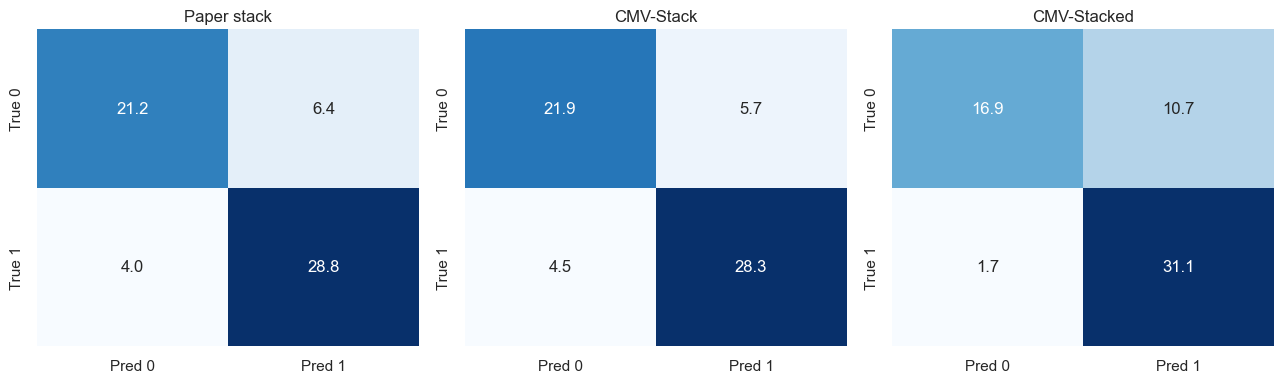

In [35]:
# Mean confusion matrices (counts per ~60-patient test fold, averaged over 50 folds)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, m, ttl in zip(axes, [PAPER, PROPOSED, "high-sensitivity"], ["Paper stack", "CMV-Stack", "CMV-Stacked"]):
    d = res[res.method == m][["TN", "FP", "FN", "TP"]].mean()
    sns.heatmap([[d.TN, d.FP], [d.FN, d.TP]], annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"]); ax.set_title(ttl)
plt.tight_layout()
plt.show()